In [1]:
import numpy as np
import matplotlib.pyplot as plt
import fastplotlib as fpl

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
🯄 | AMD Radeon Graphics (RADV REMBRANDT) | IntegratedGPU | Vulkan | Mesa 22.3.6
✅ (default) | NVIDIA T1200 Laptop GPU | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 15.0.6, 256 bits) | CPU | Vulkan | Mesa 22.3.6 (LLVM 15.0.6)
❗ | AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64) | Unknown | OpenGL | 


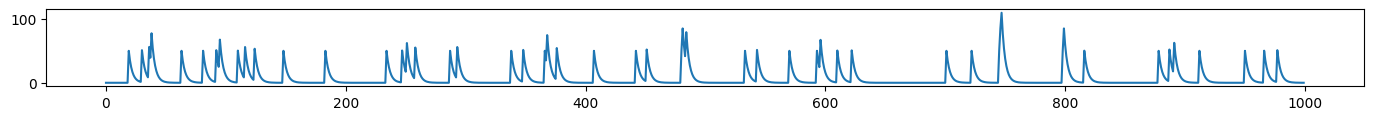

In [2]:
n_timepoints = 1_000
clean = np.zeros(n_timepoints)

x = 0
a = 0.7

b = 0

firing_prop = 0.05
spikes = (np.random.rand(n_timepoints) < firing_prop).astype(float)

for i in range(2, n_timepoints):
    clean[i] = (a * clean[i - 1]) + (b * clean[i - 2]) + (50 * spikes[i])

fig = plt.figure(figsize=(17, 1))
plt.plot(clean)

In [3]:
noise = 8

In [4]:
n_pixels = 3

series = np.zeros((n_pixels, n_timepoints))

for i in range(n_pixels):
    series[i] = clean + np.random.normal(scale=noise, size=n_timepoints)
    series[i] -= series[i].mean()

In [5]:
series[-1] = np.random.normal(scale=30, size=n_timepoints)
series[-1] -= series[-1].mean()

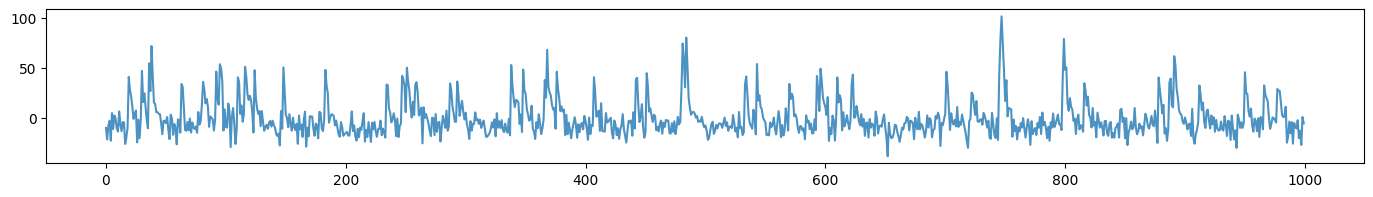

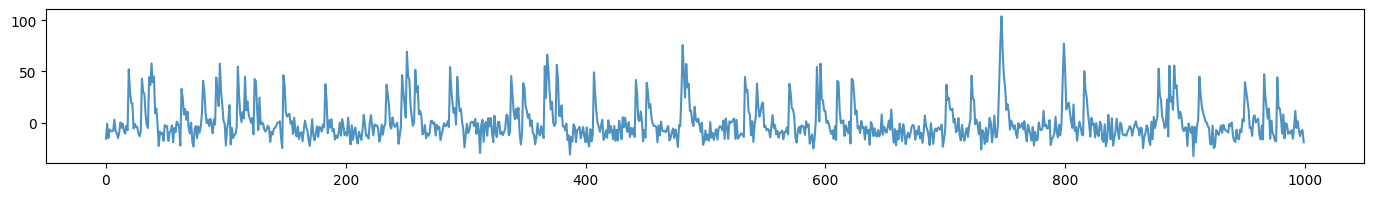

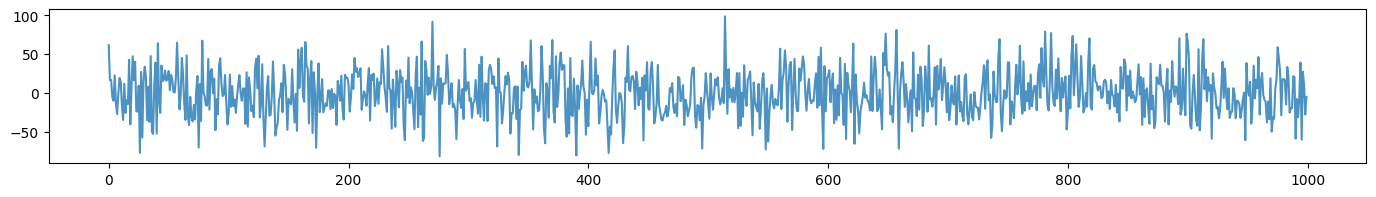

In [6]:
for i in range(n_pixels):
    fig = plt.figure(figsize=(17, 2))
    plt.plot(series[i], alpha=0.8)
    plt.show()

# plt.plot(clean, c="k", alpha=0.3)

In [7]:
series.mean(axis=1)

array([-1.13686838e-15,  0.00000000e+00, -3.41060513e-16])

In [8]:
series.std(axis=1)

array([17.7882245 , 17.66706106, 29.72339875])

In [9]:
series.ptp(axis=1)

array([140.06081225, 137.02552077, 180.87900961])

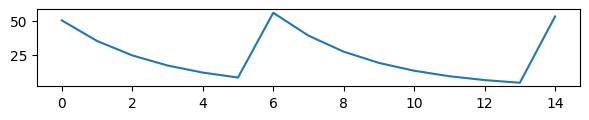

In [10]:
fig = plt.figure(figsize=(7, 1))
plt.plot(clean[110:125])

In [11]:
from scipy import linalg

In [12]:
import seaborn as sns

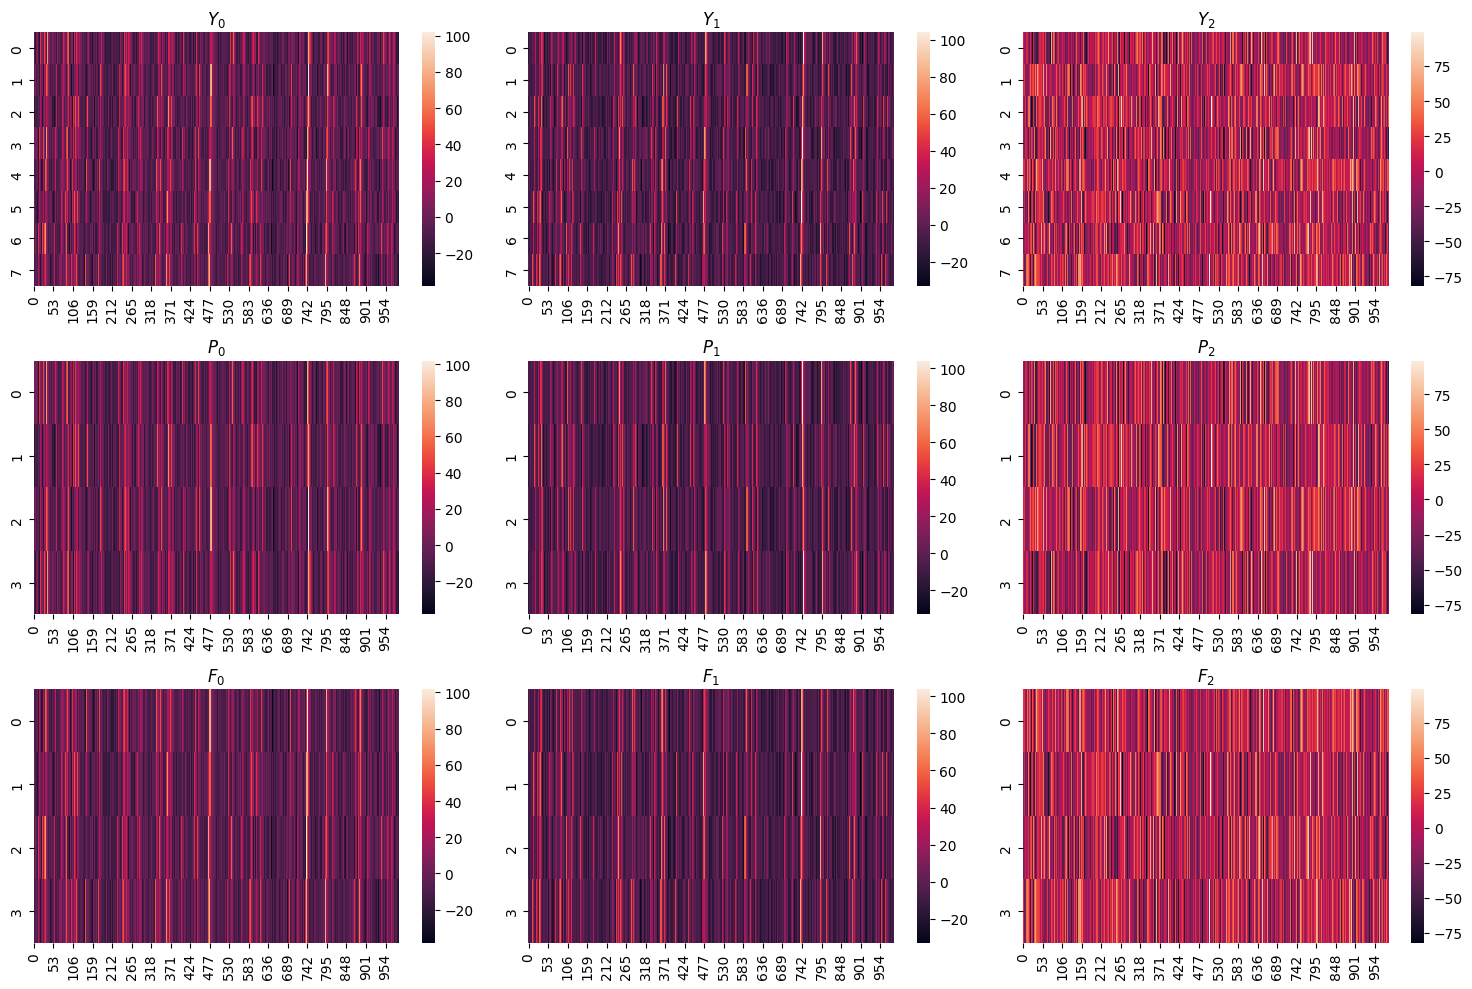

In [13]:
center = 100
w = 8

Ys = list()
Ps = list()
Fs = list()

fig, axs = plt.subplots(3, n_pixels, figsize=(15, 10))

for i in range(n_pixels):
    y = linalg.hankel(series[i, :w], series[i, w:])
    p = np.flipud(y[:int(w / 2)])
    f = y[int(w / 2):]

    Ys.append(y)
    Ps.append(p)
    Fs.append(f)
        
    sns.heatmap(y, ax=axs[0, i])
    axs[0, i].set_title(f"$Y_{i}$")

    sns.heatmap(p, ax=axs[1, i])
    axs[1, i].set_title(f"$P_{i}$")

    sns.heatmap(f, ax=axs[2, i])
    axs[2, i].set_title(f"$F_{i}$")

plt.tight_layout()

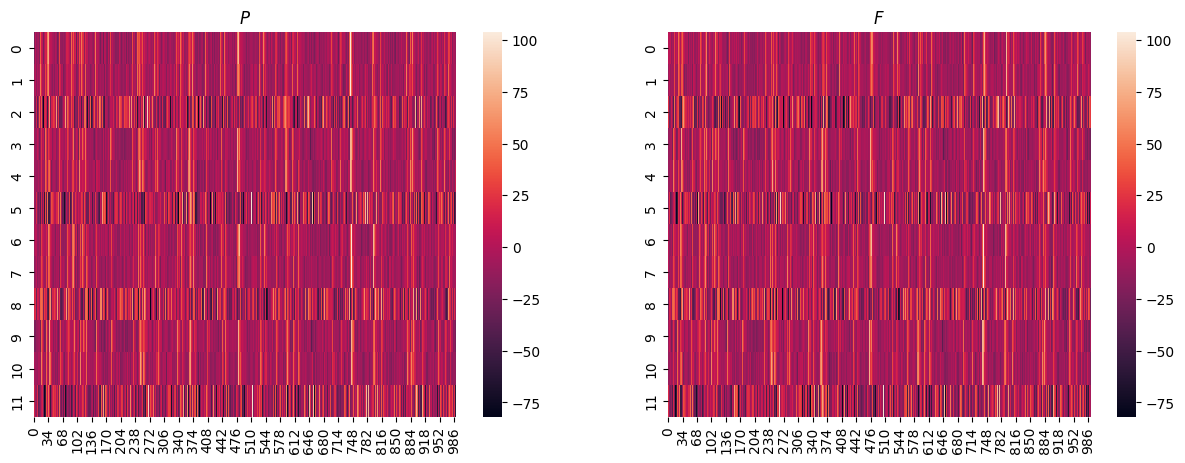

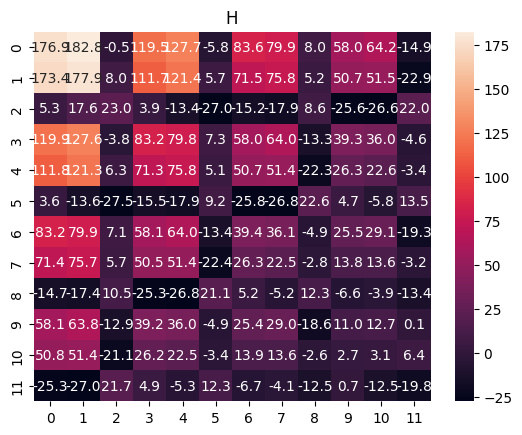

In [14]:
P_F_shape = (int(w / 2) * n_pixels, n_timepoints - w)

P = np.zeros(P_F_shape)
F = np.zeros(P_F_shape)

for i in range(n_pixels):
    P[i::n_pixels] = Ps[i]
    F[i::n_pixels] = Fs[i]

fig, axs = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(P, ax=axs[0])
axs[0].set_title(f"$P$")

sns.heatmap(F, ax=axs[1])
axs[1].set_title(f"$F$")
plt.show()

H = (F @ P.T) / P.shape[1]

sns.heatmap(H, annot=True, fmt="0.1f")
plt.title("H")
plt.show()

In [15]:
from itertools import product

In [16]:
list(product(*[range(0, int(w / 2) + n_pixels + 1, n_pixels)]*2))

[(0, 0), (0, 3), (0, 6), (3, 0), (3, 3), (3, 6), (6, 0), (6, 3), (6, 6)]

In [17]:
Hp = np.zeros((int(w / 2)**2, n_pixels**2))

for row_ix, (block_i, block_j) in enumerate(product(*[range(0, int(w / 2) * n_pixels, n_pixels)]*2)):
    Hp[row_ix] = H.T[block_i:block_i + n_pixels, block_j:block_j + n_pixels].ravel()

<Axes: >

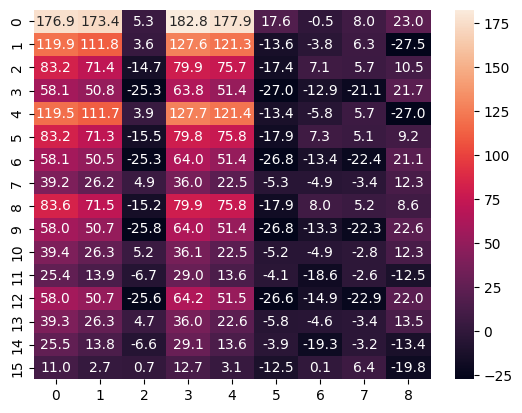

In [18]:
sns.heatmap(Hp, annot=True, fmt="0.1f")

In [19]:
u, s, v = linalg.svd(H_)

Text(0.5, 1.0, 'V')

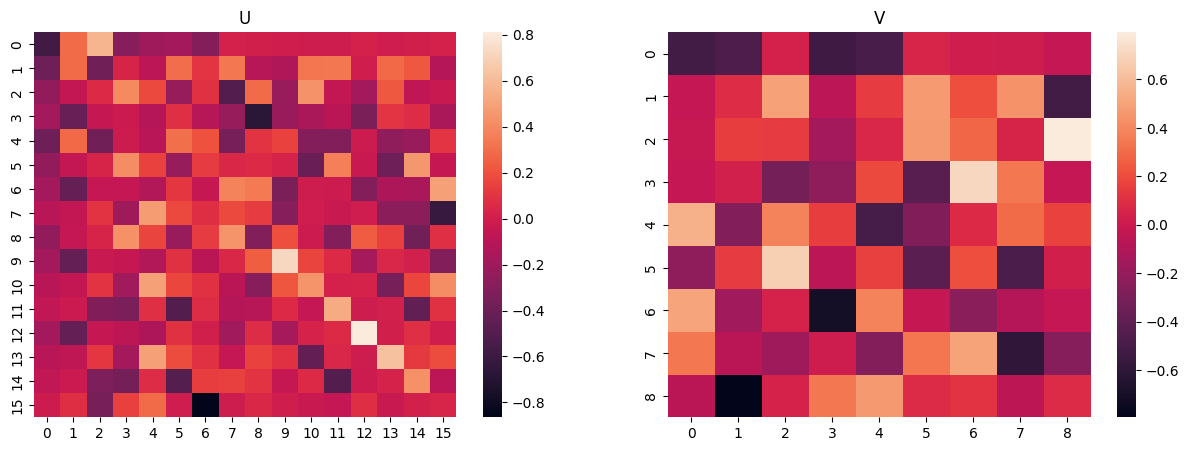

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(u, ax=axs[0])
axs[0].set_title("U")
sns.heatmap(v, ax=axs[1])
axs[1].set_title("V")

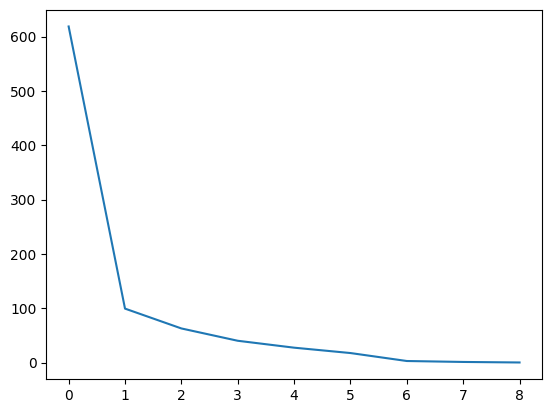

In [21]:
plt.plot(s)

Text(0.5, 1.0, 'V')

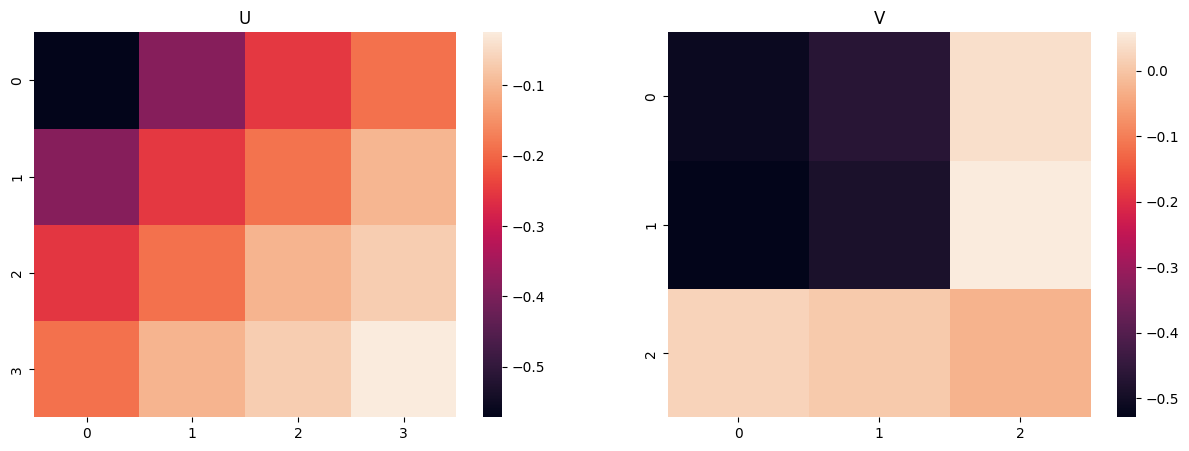

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
u_r = u[:, 0].reshape(int(w / 2), int(w / 2))
sns.heatmap(u_r, ax=axs[0])
axs[0].set_title("U")

v_r = v[0].reshape(n_pixels, n_pixels)
sns.heatmap(v_r, ax=axs[1])
axs[1].set_title("V")

<Axes: >

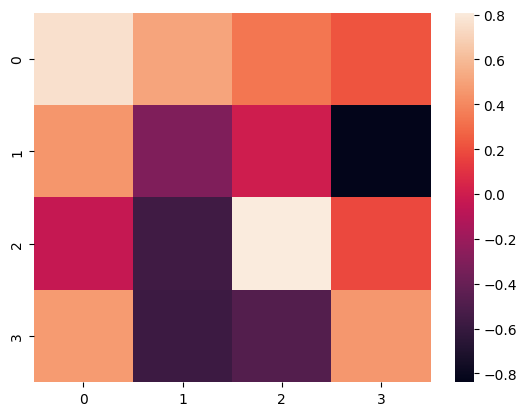

In [23]:
u_, s_, v_ = linalg.svd(u_r)

sns.heatmap(v_)

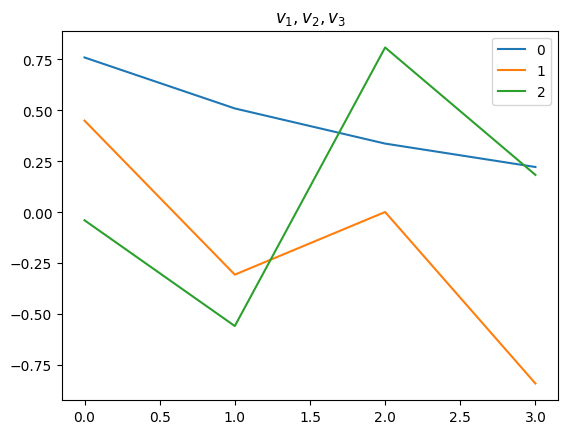

In [24]:
for i in range(3):
    plt.plot(v_[i], label=str(i))

plt.title("$v_1, v_2, v_3$")
plt.legend()
plt.show()

<Axes: >

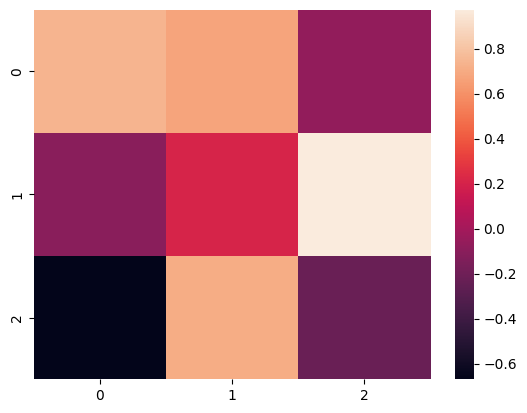

In [25]:
_, _, v_of_v = linalg.svd(v_r)

sns.heatmap(v_of_v)

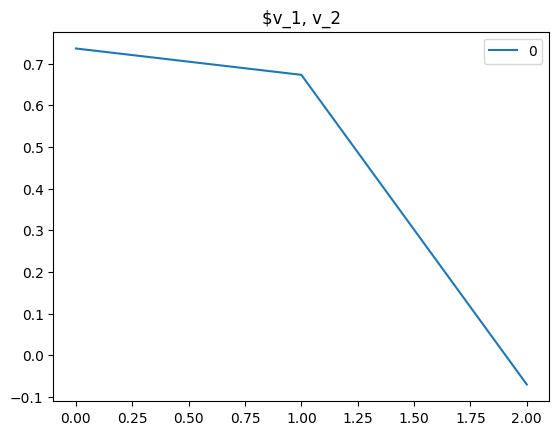

In [26]:
for i in range(1):
    plt.plot(v_of_v[i], label=str(i))

plt.title("$v_1, v_2")
plt.legend()
plt.show()

In [27]:
v_of_v[0]

array([ 0.73629954,  0.67301926, -0.07005758])

In [106]:
from scipy.spatial import distance

In [107]:
distance.cosine(v[1], v[2])

0.9999999999999999

<Axes: >

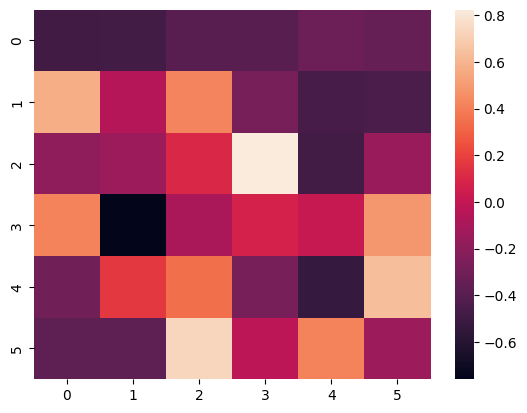

In [108]:
sns.heatmap(v)

In [60]:
filtered = np.zeros(shape=(3, n_timepoints))
filtered[:, int(w / 2) * n_pixels:] = v[::2, :3] @ P[::2]

indices = slice(0, 500)
fig = plt.figure(figsize=(35, 5))
plt.plot(clean[indices], label="data", linewidth=3)
for i in range(filtered.shape[0]):
    plt.plot(filtered[i][indices], label=i + 1, alpha=0.7)
plt.legend()
plt.show()

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 5 is different from 3)

In [70]:
v[:3].shape

(3, 10)

In [68]:
P.shape

(10, 990)

In [56]:
(v[:3] @ P).shape

(3, 990)

In [54]:
filtered.shape

(3, 990)

In [55]:
P.shape

(10, 990)

In [113]:
v[:3].shape

(3, 15)

In [114]:
filtered.shape

(3, 220)

# Reconstruct or denoise the entire signal using the kernels? 

In [25]:
P.ptp()

97.00020683091903

In [25]:
pc

array(0.)

In [32]:
cov = np.cov(X)

<Axes: >

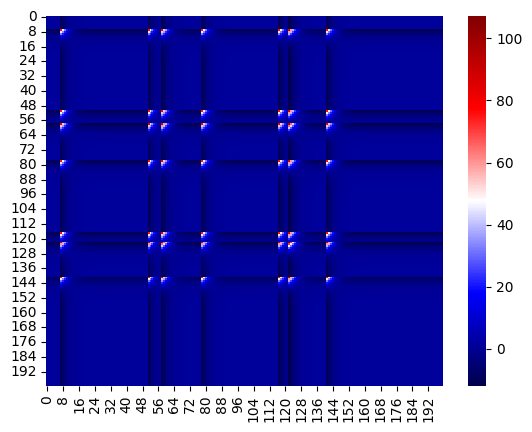

In [33]:
sns.heatmap(cov, cmap="seismic")

# Try this with noise and hankel matrices